# Biến đổi Fourier liên tục và rời rạc 2 chiều

Biến đổi Fourier 2 chiều là công cụ nền tảng trong xử lý ảnh, thị giác máy tính và nhiều lĩnh vực kỹ thuật khác. Tùy theo bản chất tín hiệu (liên tục hay rời rạc), ta sử dụng biến đổi Fourier liên tục hoặc biến đổi Fourier rời rạc.

---

# I. Biến đổi Fourier liên tục 2 chiều

## Định nghĩa

Với hàm liên tục $f(t, z)$:

$$
F(\mu, \nu) 
= 
\int_{-\infty}^{\infty}
\int_{-\infty}^{\infty}
f(t, z)\,
e^{-i (\mu t + \nu z)}
\, dt \, dz
$$

Trong đó:

- $t, z$ là biến không gian,
- $\mu, \nu$ là biến tần số tương ứng,
- $F(\mu, \nu)$ là phổ liên tục 2 chiều.

---

## Biến đổi ngược

$$
f(t, z)
=
\frac{1}{(2\pi)^2}
\int_{-\infty}^{\infty}
\int_{-\infty}^{\infty}
F(\mu, \nu)\,
e^{i (\mu t + \nu z)}
\, d\mu \, d\nu
$$

---

# II. Biến đổi Fourier rời rạc 2 chiều (2D DFT)

Trong thực tế, ảnh số và dữ liệu đo đạc là rời rạc và hữu hạn. Khi đó ta sử dụng DFT 2 chiều.

Giả sử ảnh số:

$$
f[m,n], 
\quad 
m = 0,1,\dots,M-1, 
\quad 
n = 0,1,\dots,N-1
$$

---

## 1️⃣ Định nghĩa DFT 2D

$$
F[k,\ell]
=
\sum_{m=0}^{M-1}
\sum_{n=0}^{N-1}
f[m,n]\;
e^{-i2\pi\left(\frac{k m}{M} + \frac{\ell n}{N}\right)}
$$

trong đó:

- $k = 0,1,\dots,M-1$
- $\ell = 0,1,\dots,N-1$
- $F[k,\ell]$ là phổ rời rạc 2 chiều.

---

## 2️⃣ Biến đổi ngược (iDFT 2D)

$$
f[m,n]
=
\frac{1}{MN}
\sum_{k=0}^{M-1}
\sum_{\ell=0}^{N-1}
F[k,\ell]\;
e^{i2\pi\left(\frac{k m}{M} + \frac{\ell n}{N}\right)}
$$

---

# III. FFT 2 chiều

FFT (Fast Fourier Transform) 2D là thuật toán nhanh để tính DFT 2D.

Vì DFT 2D có độ phức tạp:

$$
O(MN \cdot MN)
$$

FFT 2D giảm xuống:

$$
O(MN \log(MN))
$$

Trong thực tế, FFT 2D được thực hiện bằng:

1. Tính FFT theo từng hàng
2. Tính FFT theo từng cột

---

# IV. So sánh liên tục và rời rạc

| Tính chất | Fourier liên tục 2D | DFT 2D |
|------------|---------------------|---------|
| Miền không gian | Liên tục | Rời rạc hữu hạn |
| Miền tần số | Liên tục | Rời rạc tuần hoàn |
| Tích phân / Tổng | Tích phân kép | Tổng kép |
| Ứng dụng | Lý thuyết | Ảnh số, dữ liệu số |

---

# V. Ý nghĩa thực tiễn

Trong xử lý ảnh số:

- Ảnh là ma trận $f[m,n]$
- Phổ $F[k,\ell]$ cho biết mức đóng góp của các tần số theo hai chiều
- Lọc ảnh được thực hiện bằng cách thao tác trên $F[k,\ell]$

---

# Kết luận

Biến đổi Fourier 2 chiều:

- Dạng liên tục dùng cho mô hình lý thuyết.
- Dạng rời rạc (DFT/FFT) dùng cho xử lý số thực tế.

Hiểu rõ cả hai giúp ta nắm được bản chất toán học lẫn cách triển khai trên máy tính.

# I . Visualization for 2D Square Signal
To visualize a 2D square signal and its Fourier transform in Python, you can use libraries such as NumPy for numerical operations and Matplotlib for plotting. Here's a Python script that generates a 2D square signal (often represented as a box function in two dimensions), computes its Fourier transform using the Fast Fourier Transform (FFT), and visualizes both the signal and its Fourier spectrum:

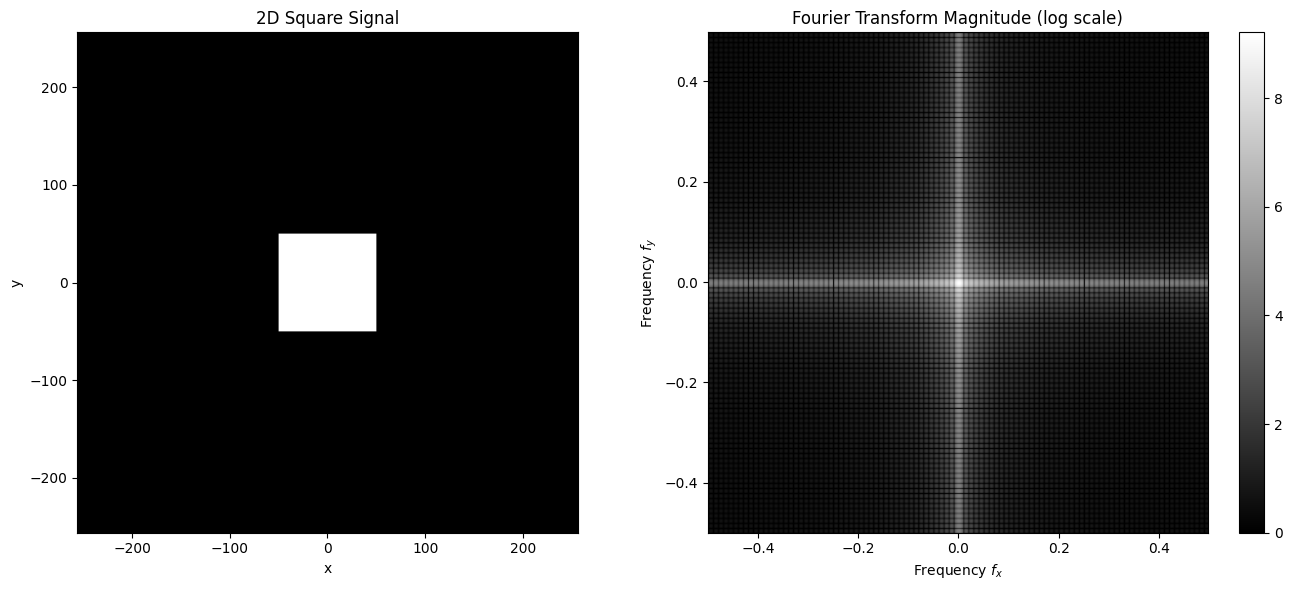

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fftshift, fft2

# ----------------------------
# Parameters
# ----------------------------
size = 512
center = size // 2
length = 100

dx = 1.0   # spatial sampling interval (Δx)
dy = 1.0   # spatial sampling interval (Δy)

# ----------------------------
# Create 2D square signal
# ----------------------------
square_signal = np.zeros((size, size))
square_signal[
    center-length//2:center+length//2,
    center-length//2:center+length//2
] = 1

# ----------------------------
# 2D FFT
# ----------------------------
F = fftshift(fft2(square_signal))

# ----------------------------
# Frequency axes
# ----------------------------
fx = np.fft.fftshift(np.fft.fftfreq(size, d=dx))
fy = np.fft.fftshift(np.fft.fftfreq(size, d=dy))

# ----------------------------
# Plot
# ----------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Original signal
ax[0].imshow(square_signal, cmap='gray',
             extent=[-size/2*dx, size/2*dx, -size/2*dy, size/2*dy])
ax[0].set_title('2D Square Signal')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')

# Fourier magnitude
im = ax[1].imshow(
    np.log(np.abs(F)+1),
    cmap='gray',
    extent=[fx.min(), fx.max(), fy.min(), fy.max()],
    aspect='auto'
)

ax[1].set_title('Fourier Transform Magnitude (log scale)')
ax[1].set_xlabel('Frequency $f_x$')
ax[1].set_ylabel('Frequency $f_y$')

plt.colorbar(im, ax=ax[1])
plt.tight_layout()
plt.show()

# II. Visualize 2D square signal in a 3D axes


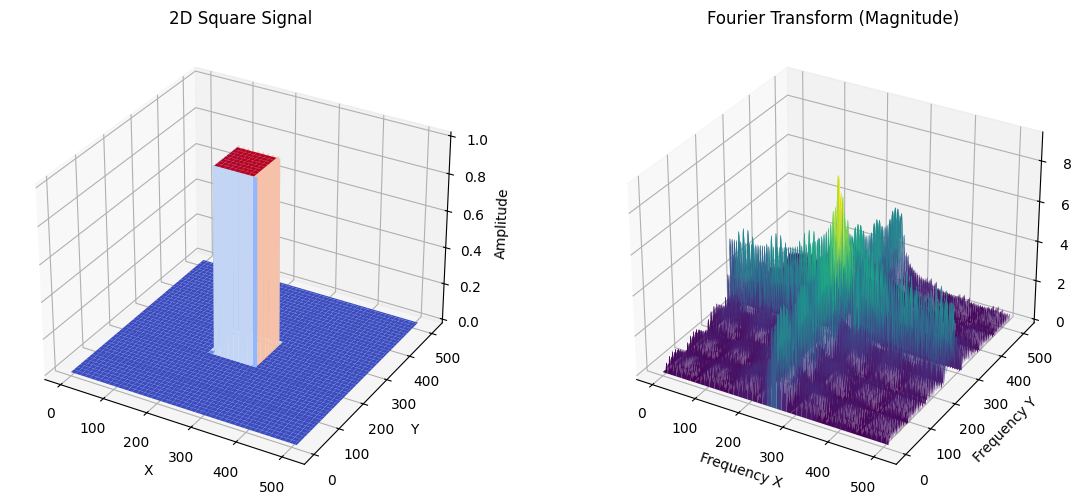

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.fftpack import fftshift, fft2

# Parameters
size = 512           # Size of the 2D grid
center = size // 2   # Center point
length = 100         # Length of the square side

# Create a 2D square signal (box function)
square_signal = np.zeros((size, size))
square_signal[center-length//2:center+length//2, center-length//2:center+length//2] = 1

# Compute the 2D Fourier Transform
F = fftshift(fft2(square_signal))

# 3D Plotting
fig = plt.figure(figsize=(14, 6))

# Plot for the square signal
ax1 = fig.add_subplot(121, projection='3d')
x = np.arange(0, size)
y = np.arange(0, size)
X, Y = np.meshgrid(x, y)
ax1.plot_surface(X, Y, square_signal, cmap=cm.coolwarm, edgecolor='none')
ax1.set_title('2D Square Signal')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Amplitude')

# Plot for the Fourier Transform
ax2 = fig.add_subplot(122, projection='3d')
magnitude = np.log(np.abs(F) + 1)  # Logarithmic scale
ax2.plot_surface(X, Y, magnitude, cmap=cm.viridis, edgecolor='none')
ax2.set_title('Fourier Transform (Magnitude)')
ax2.set_xlabel('Frequency X')
ax2.set_ylabel('Frequency Y')
ax2.set_zlabel('Magnitude')

plt.show()

# Biến đổi Fourier 2 chiều – Ví dụ với xung Dirac 2D

## Biến đổi Fourier liên tục 2 chiều

Biến đổi Fourier 2 chiều của một hàm $f(t, z)$ được định nghĩa như sau:

$$
F(\mu, \nu) 
= 
\int_{-\infty}^\infty 
\int_{-\infty}^\infty 
f(t, z)\, 
e^{-j 2\pi (\mu t + \nu z)} 
\, dt \, dz
$$

Trong đó:

- $f(t, z)$ là tín hiệu đầu vào hoặc hàm ảnh, với $t$ và $z$ là các tọa độ không gian hoặc thời gian.
- $\mu$ và $\nu$ là các tần số không gian tương ứng với $t$ và $z$.
- $F(\mu, \nu)$ là hàm phức biểu diễn biên độ và pha của tín hiệu tại các tần số khác nhau.
- $j$ là đơn vị ảo ($j^2 = -1$).

---

## Biến đổi Fourier ngược 2 chiều

Quá trình ngược lại để khôi phục hàm ban đầu từ phổ tần số được cho bởi:

$$
f(t, z) 
= 
\int_{-\infty}^\infty 
\int_{-\infty}^\infty 
F(\mu, \nu)\, 
e^{j 2\pi (\mu t + \nu z)} 
\, d\mu \, d\nu
$$

---

## Áp dụng cho hàm Dirac delta 2 chiều

Hàm Dirac $\delta(t, z)$ là một khái niệm cơ bản trong toán học lý thuyết và ứng dụng. Nó mô tả một xung lý tưởng:

- Biên độ vô hạn
- Diện tích bằng 1
- Tập trung tại một điểm duy nhất

### Biến đổi thuận

Biến đổi Fourier của $\delta(t, z)$ rất đơn giản:

$$
F(\mu, \nu)
=
\int_{-\infty}^\infty 
\int_{-\infty}^\infty 
\delta(t, z)\,
e^{-j 2\pi (\mu t + \nu z)}
\, dt \, dz
=
1
$$

Nghĩa là:

> Phổ của một xung Dirac 2D bằng 1 tại mọi tần số.

Điều này xảy ra vì tích phân của hàm mũ phức khi nhân với Dirac chỉ “lấy giá trị tại điểm 0”, và $e^{0} = 1$.

---

### Biến đổi ngược

Ngược lại, nếu phổ là hằng số:

$$
F(\mu, \nu) = 1
$$

thì biến đổi Fourier ngược sẽ cho:

$$
f(t, z)
=
\int_{-\infty}^\infty 
\int_{-\infty}^\infty 
1 \cdot e^{j 2\pi (\mu t + \nu z)}
\, d\mu \, d\nu
=
\delta(t, z)
$$

---

## Ý nghĩa vật lý và ứng dụng

Tính chất này thể hiện rằng:

- Một xung cực nhỏ trong miền không gian
- Tương ứng với phổ phẳng (chứa mọi tần số) trong miền tần số

Đây là nền tảng quan trọng để:

- Phân tích đáp ứng xung của hệ thống
- Thiết kế bộ lọc
- Phân tích nguồn điểm trong quang học, âm học và cơ học lượng tử

---

## Trong ứng dụng số

Trong xử lý ảnh số, ta không thể tạo một Dirac lý tưởng (vô hạn biên độ). Thay vào đó:

- Một điểm ảnh duy nhất có giá trị khác 0
- Các điểm khác bằng 0

được xem là xấp xỉ của xung Dirac 2D.

Điều này vẫn giữ nguyên bản chất:

> Điểm càng tập trung trong miền không gian → phổ càng trải rộng trong miền tần số.

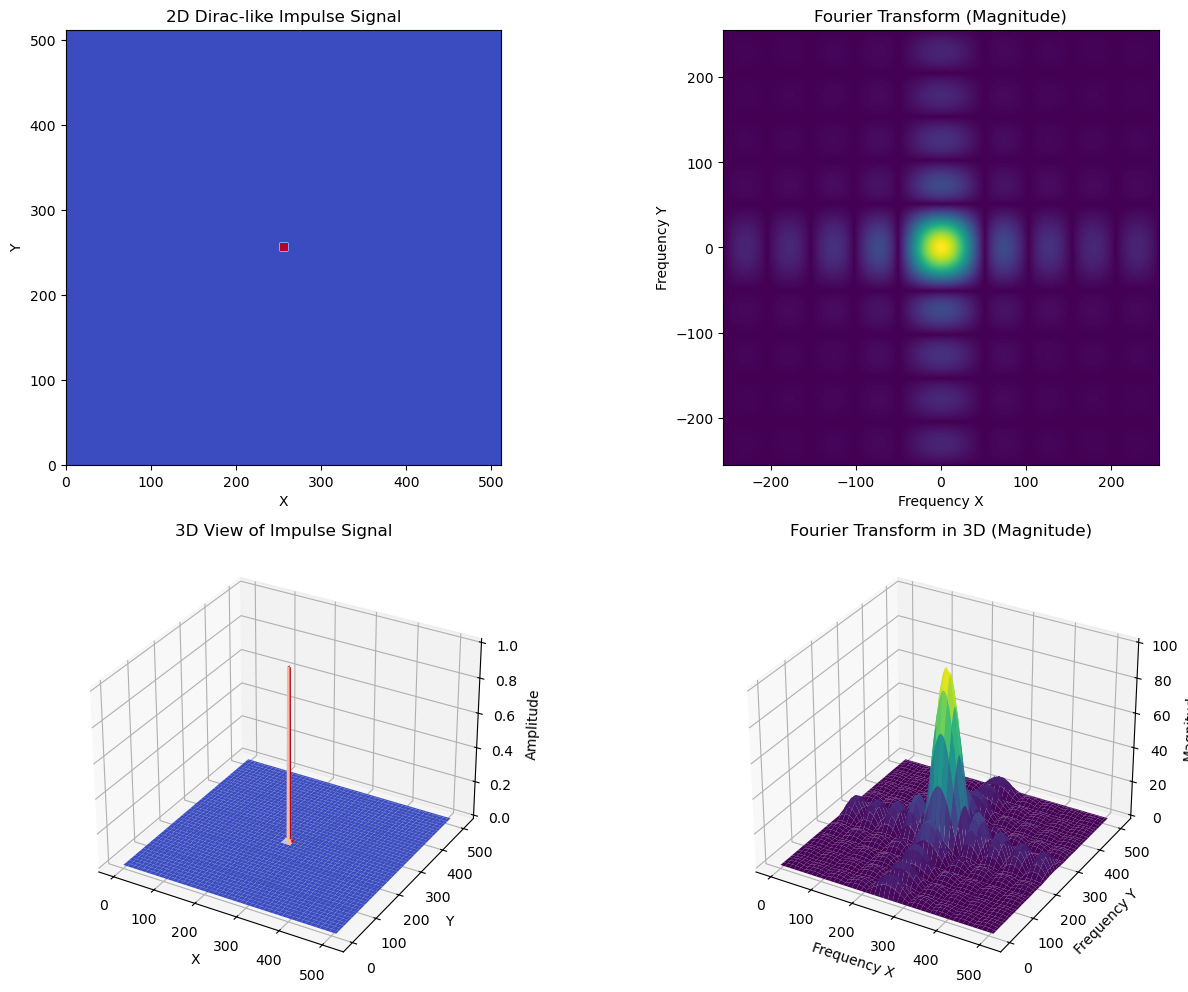

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.fftpack import fftshift, fft2

# Parameters
size = 512          # Size of the 2D grid
center = size // 2  # Center point
width = 10          # Width of the square impulse

# Create a 2D Dirac-like impulse using a narrow square signal
impulse_signal = np.zeros((size, size))
impulse_signal[center-width//2:center+width//2, center-width//2:center+width//2] = 1

# Compute the 2D Fourier Transform
F = fftshift(fft2(impulse_signal))

# Setup plots
fig = plt.figure(figsize=(14, 10))

# 2D plots
ax1 = fig.add_subplot(221)
ax1.imshow(impulse_signal, cmap=cm.coolwarm, extent=[0, size, 0, size])
ax1.set_title('2D Dirac-like Impulse Signal')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')

ax2 = fig.add_subplot(222)
ax2.imshow(np.abs(F), cmap=cm.viridis, extent=[-size/2, size/2, -size/2, size/2])
ax2.set_title('Fourier Transform (Magnitude)')
ax2.set_xlabel('Frequency X')
ax2.set_ylabel('Frequency Y')

# 3D plots
ax3 = fig.add_subplot(223, projection='3d')
x = np.arange(0, size)
y = np.arange(0, size)
X, Y = np.meshgrid(x, y)
ax3.plot_surface(X, Y, impulse_signal, cmap=cm.coolwarm, edgecolor='none')
ax3.set_title('3D View of Impulse Signal')
ax3.set_xlabel('X')
ax3.set_ylabel('Y')
ax3.set_zlabel('Amplitude')

ax4 = fig.add_subplot(224, projection='3d')
magnitude = np.abs(F)  # Magnitude of the Fourier transform
ax4.plot_surface(X, Y, magnitude, cmap=cm.viridis, edgecolor='none')
ax4.set_title('Fourier Transform in 3D (Magnitude)')
ax4.set_xlabel('Frequency X')
ax4.set_ylabel('Frequency Y')
ax4.set_zlabel('Magnitude')

plt.tight_layout()
plt.show()